<a href="https://colab.research.google.com/github/mohamadrezanikmaram/facial_emotion_recognition/blob/main/src_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **import libraries**

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras

### **transfer train and test data to colab from drive for much speed**

In [ ]:
!cp -r /content/drive/MyDrive/Facial_Emotion_Recognition/data /content/data

## **read and save test/train data and classification emotions**

In [ ]:
#calssification facial emotion
face_emotions = ['angry', 'happy', 'neutral', 'sad', 'surprise']

# read train data and save
train_img = []
train_label = []
for emotion in face_emotions:
    folder = f"/content/data/datasets/face/train/{emotion}"
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        img = cv2.imread(path)
        if img is not None:
            train_img.append(img)
            train_label.append(emotion)

#read test datas and save
test_img = []
test_label = []
for emotion in face_emotions:
    folder = f"/content/data/datasets/face/test/{emotion}"
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        img = cv2.imread(path)
        if img is not None:
            test_img.append(img)
            test_label.append(emotion)


print("train and test datas in readed and saved...")



## **some info of datas and their shape**

In [ ]:

# convert images to np array for checking te image info
train_img = np.array(train_img)
train_label = np.array(train_label)
test_img = np.array(test_img)
test_label = np.array(test_label)

#images info
print("number of Train Images:", len(train_img))

print("train_img shape:", train_img.shape)

print("train_label shape:", train_label.shape)

print("number of Test Images:", len(test_img))

print("test_img shape:", test_img.shape)

print("test_label shape:", test_label.shape)

print(f"pictures data type(dtype): {train_img.dtype}")
# max and min number of pixels in train images
print(f"min & max number of pixels in train picture: min={train_img.min()}, max={train_img.max()}")

import numpy as np

# founding the number of picture in each class for data agumantation
classes, counts = np.unique(train_label, return_counts=True)
emotion_names = ['angry', 'happy', 'neutral', 'sad', 'surprise']

for emotion_idx, count in zip(classes, counts):
    print(f"{emotion_names[emotion_idx]}: {count} picture")

تعداد Train Images: 24176
train_img shape: (24176, 48, 48, 3)
train_label shape: (24176,)
تعداد Test Images: 6043
test_img shape: (6043, 48, 48, 3)
test_label shape: (6043,)
نوع داده تصاویر (dtype): uint8
حداقل و حداکثر مقدار پیکسل‌ها: min=0, max=255


TypeError: list indices must be integers or slices, not numpy.str_

## **show a sample image**

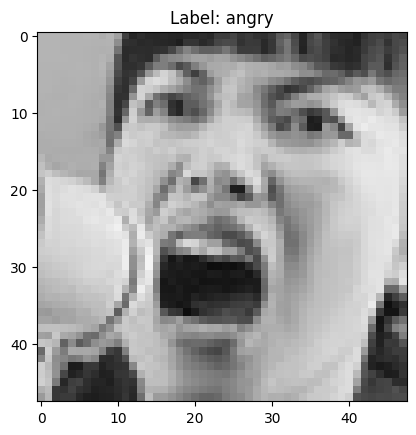

In [ ]:
# choosing a picture and show in matoplotlib
index = 0
sample_img = train_img[index]
sample_label = train_label[index]

#show image
plt.close()

plt.imshow(sample_img)
plt.title(f"Label: {sample_label}")
plt.show()


## **to ready data for process**

In [ ]:
#encoding str label to numeric label
emotion_to_index = {
    'angry': 0,
    'happy': 1,
    'neutral': 2,
    'sad': 3,
    'surprise': 4
}

#convert labels list to numeric type
train_label = np.array([emotion_to_index[label] for label in train_label])
test_label = np.array([emotion_to_index[label] for label in test_label])

# changing the 3 to 1 (colorfull to gray) for more careful process
train_img_final = []
for img in train_img:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    #adding a dimantion
    train_img_final.append(gray[..., None])

# changing the 3 to 1 (colorfull to gray) for more careful process
test_img_final = []
for img in test_img:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    #adding a dimantion
    test_img_final.append(gray[..., None])

#convert to np array
train_img_final = np.array(train_img_final)
test_img_final = np.array(test_img_final)

print("train_img_final shape befor normalizing:", train_img_final.shape)
print("test_img_final shape befor normalizing::", test_img_final.shape)

#normilizing number of pixels (0-255 to 0-1)
test_img_final , train_img_final = (test_img_final)/255.0 , (train_img_final)/255.0

print("test and train label encod:")
print(train_label)
print(test_label)

print("train_img_final shape after normalizing:", train_img_final.shape)
print("test_img_final shape after normalizing::", test_img_final.shape)

train_img_final shape befor normalizing: (24176, 48, 48, 1)
test_img_final shape befor normalizing:: (6043, 48, 48, 1)
test and train label encod:
[0 0 0 ... 4 4 4]
[0 0 0 ... 4 4 4]
train_img_final shape after normalizing: (24176, 48, 48, 1)
test_img_final shape after normalizing:: (6043, 48, 48, 1)


**show new picture that are changed(gray color and normilized and add dim)**

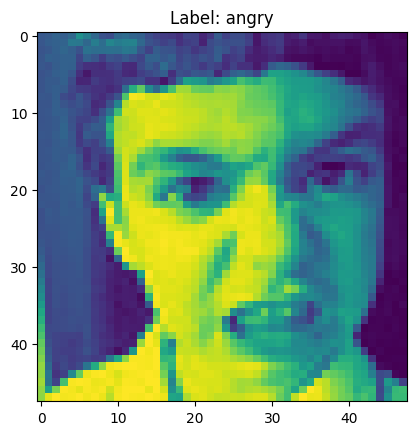

sample shape: (48, 48, 1)


In [ ]:
#show changed sample
sample = train_img_final[1]
sample_label = train_label[1]
plt.imshow(sample)
plt.title(f"Label: {face_emotions[sample_label]}")
plt.show()

print(f"sample shape: {sample.shape}")

#sample = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


## **Data Augmentation**

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# computin the weight for each class
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_label),
    y=train_label
)

#  change to dict because tensorflwo need to dict for fit method
class_weights_dict = dict(enumerate(class_weights))

print("the computed weight for each class:")
for idx, weight in class_weights_dict.items():
    print(f"class {idx} : {weight:.4f}")

وزن‌های محاسبه شده برای کلاس‌ها (به ترتیب از 0 تا 4):
کلاس 0: 1.2103
کلاس 1: 0.6702
کلاس 2: 0.9739
کلاس 3: 1.0011
کلاس 4: 1.5248


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, LeakyReLU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("building architecture for CNN...")

def create_fer_cnn():
    model = Sequential([
        # first CNN block (input layer)
        Conv2D(32, (3, 3), padding='same', input_shape=(48, 48, 1)),
        BatchNormalization(),
        LeakyReLU(alpha=0.1),

        Conv2D(64, (3, 3), padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=0.1),


        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        # second CNN block (headen layers)
        Conv2D(128, (3, 3), padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=0.1),

        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        #  third CNN block
        Conv2D(256, (3, 3), padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=0.1),

        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        #final layer flatten   (Fully Connected)
        Flatten(),
        Dense(512),
        BatchNormalization(),
        LeakyReLU(alpha=0.1),
        Dropout(0.5),

        # output layer with 5 classes
        Dense(5, activation='softmax')
    ])

    return model

# creat model
model = create_fer_cnn()

# compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # چون لیبل‌ها به صورت عدد صحیح (0 تا 4) هستند
    metrics=['accuracy']
)

#show a summary of cnn model and parameters and...

print("summary of cnn model:")
model.summary()


#define smart callback for controling learning speed and avoid overfiting
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# final setting for model education
EPOCHS = 50
BATCH_SIZE = 64

print(" starting learning process (Model Training)... \n")

# running fit method
history = model.fit(
    train_img_final, train_label,                # داده‌ها و لیبل‌های آموزشی
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(test_img_final, test_label),  # داده‌های اعتبارسنجی
    class_weight=class_weights_dict,             # وزن‌های محاسبه شده برای حل نامتعادلی کلاس‌ها
    callbacks=[reduce_lr, early_stopping],       # کالبک‌های بهینه‌ساز
    verbose=1
)

print("the model education id finished sucsess...")

در حال ساخت معماری سفارشی CNN...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 5,113,477 (19.51 MB)

 Trainable params: 5,111,493 (19.50 MB)

 Non-trainable params: 1,984 (7.75 KB)


شروع فرآیند آموزش مدل (Model Training)...
Epoch 1/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 45s 69ms/step - accuracy: 0.4107 - loss: 1.5073 - val_accuracy: 0.2347 - val_loss: 1.7579 - learning_rate: 0.0010
Epoch 2/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.5418 - loss: 1.1314 - val_accuracy: 0.5871 - val_loss: 1.0406 - learning_rate: 0.0010
Epoch 3/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.6024 - loss: 1.0008 - val_accuracy: 0.6091 - val_loss: 0.9783 - learning_rate: 0.0010
Epoch 4/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6335 - loss: 0.9308 - val_accuracy: 0.6119 - val_loss: 0.9775 - learning_rate: 0.0010
Epoch 5/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6536 - loss: 0.8788 - val_accuracy: 0.6383 - val_loss: 0.9330 - learning_rate: 0.0010
Epoch 6/50
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6725 - loss: 0.8397 - val_accuracy: 0.6427 - val_loss: 0.9265 - learning_rate: 0.0010
Epoch 7/50
378/378 ━━━━━━━━━━━━━━━━━━━

## **save model file in folder**

In [ ]:
from google.colab import drive
import os

# connect colab to drive
drive.mount('/content/drive')

#path for saving model file
drive_models_dir = '/content/drive/MyDrive/Facial_Emotion_Recognition/models'

# path and file name
model_path = os.path.join(drive_models_dir, 'face_model.keras')

#saving the model
model.save(model_path)

print(f"model saved in folder:\n{model_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
مدل با موفقیت در گوگل درایو ذخیره شد:
/content/drive/MyDrive/Facial_Emotion_Recognition/models/face_model.keras


## **show model info with plots**

تاریخچه‌ی آموزش (History) با موفقیت در درایو ذخیره شد:
/content/drive/MyDrive/Facial_Emotion_Recognition/models/face_model_history.pkl

--- 📊 اطلاعات کلیدی و عملکرد مدل ---
🏆 بالاترین دقت ارزیابی (Best Val Accuracy): 71.17% (مربوط به دور 24)
🎯 آخرین دقت آموزش (Final Train Accuracy): 92.83%
📉 آخرین خطای آموزش (Final Train Loss): 0.1900
📉 آخرین خطای ارزیابی (Final Val Loss): 1.0705


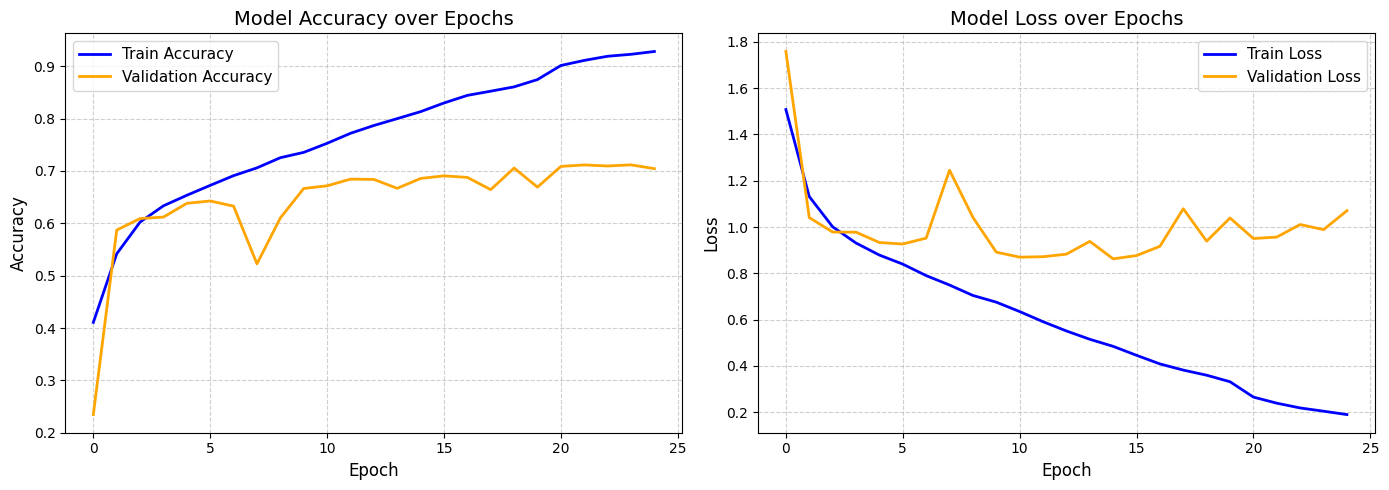

In [ ]:
import pickle
import matplotlib.pyplot as plt
import os

#path for saving info  in drive
drive_models_dir = '/content/drive/MyDrive/Facial_Emotion_Recognition/models'
os.makedirs(drive_models_dir, exist_ok=True)
history_path = os.path.join(drive_models_dir, 'face_model_history.pkl')

#saving history var with pickle library
with open(history_path, 'wb') as f:
    pickle.dump(history.history, f)

print(f"the history method info saved :\n{history_path}\n")

#  استخراج و نمایش اطلاعات کلیدی
history_dict = history.history
#max of accuracy(best accuracy for model)
best_val_acc = max(history_dict['val_accuracy'])
#best repeat number for learning
best_epoch = history_dict['val_accuracy'].index(best_val_acc) + 1

print(" \t\t\tاطلاعات کلیدی و عملکرد مدل\t\t\t")
print(f" بالاترین دقت ارزیابی (Best Val Accuracy): {best_val_acc * 100:.2f}% (مربوط به دور {best_epoch})")
print(f" آخرین دقت آموزش (Final Train Accuracy): {history_dict['accuracy'][-1] * 100:.2f}%")
print(f"آخرین خطای آموزش (Final Train Loss): {history_dict['loss'][-1]:.4f}")
print(f" آخرین خطای ارزیابی (Final Val Loss): {history_dict['val_loss'][-1]:.4f}")

print("\n\n")
#(Accuracy & Loss Plots) رسم نمودارهای پیشرفت دقت و خطا
plt.figure(figsize=(14, 5))

#(Accuracy) نمودار دقت
plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'], label='Train Accuracy', linewidth=2, color='blue')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy', linewidth=2, color='orange')
plt.title('Model Accuracy over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

#(Loss) نمودار خطا
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'], label='Train Loss', linewidth=2, color='blue')
plt.plot(history_dict['val_loss'], label='Validation Loss', linewidth=2, color='orange')
plt.title('Model Loss over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## **testing model with test images**

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


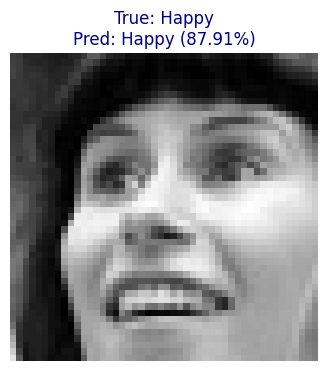

📌 لیبل واقعی: Happy
🤖 تشخیص مدل: Happy با اطمینان 87.91%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

#choose random index for choosing random picture
random_index = random.randint(0, len(test_img_final) - 1)

# extract picture and its label
sample_image = test_img_final[random_index]
true_label_idx = test_label[random_index]

# to ready image for model

img_to_predict = np.expand_dims(sample_image, axis=0)

# load model and predict
predictions = loaded_model.predict(img_to_predict)[0]
predicted_index = np.argmax(predictions)

# classes name that are ordered
emotion_labels = ['Angry', 'Happy', 'Neutral', 'Sad', 'Surprise']

true_emotion = emotion_labels[true_label_idx]
predicted_emotion = emotion_labels[predicted_index]
confidence = predictions[predicted_index] * 100

#show picture and model predict
plt.figure(figsize=(4, 4))
plt.imshow(sample_image.squeeze(), cmap='gray')
plt.title(f"True: {true_emotion}\nPred: {predicted_emotion} ({confidence:.2f}%)",
          fontsize=12, color='darkblue' if true_emotion == predicted_emotion else 'darkred')
plt.axis('off')
plt.show()

print(f" real label: {true_emotion}")
print(f"model recognitio: {predicted_emotion} with confidence {confidence:.2f}%")

## recogning and crop face

In [ ]:
import cv2
import os

# path of folder and picture in Google Drive
folder_path = '/content/drive/MyDrive/Facial_Emotion_Recognition'
img_name = 'face_picture1.jpg'  # the picture name
img_path = os.path.join(folder_path, img_name)

# read the image
img_cv2 = cv2.imread(img_path)

if img_cv2 is not None:
    gray_cv2 = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2GRAY)

    # recogniotion face with opencv library
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    faces = face_cascade.detectMultiScale(gray_cv2, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    if len(faces) > 0:
        (x, y, w, h) = faces[0]
        # Crop face
        cropped_face = img_cv2[y:y+h, x:x+w]

        # save cropped picture
        output_path = os.path.join(folder_path, 'cropped_face.jpg')
        cv2.imwrite(output_path, cropped_face)
        print(f" the picture cropped and saved in path :\n{output_path}")
    else:
        print("the face not found or not recognied in the picture!")
else:
  print(f"the picture not found in :\n{img_path} folder !...")

 the picture cropped and saved in path :
/content/drive/MyDrive/Facial_Emotion_Recognition/cropped_face.jpg


## **predict emotion**

model loaded sucsess.

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


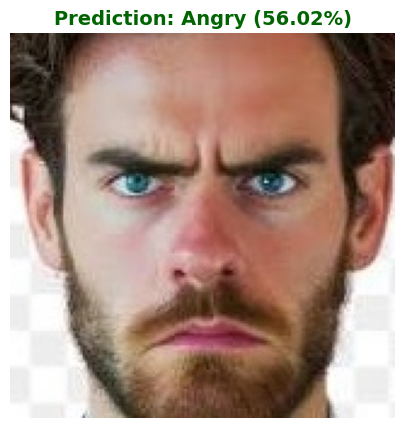

 Model prediction details for this image :
 - Angry: 56.02%
 - Happy: 0.00%
 - Neutral: 39.48%
 - Sad: 4.48%
 - Surprise: 0.01%


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os

#emotions list
emotion_labels = ['Angry', 'Happy', 'Neutral', 'Sad', 'Surprise']

# path of image
img_path = '/content/drive/MyDrive/Facial_Emotion_Recognition/cropped_face.jpg'

# load model to program
model_path = '/content/drive/MyDrive/Facial_Emotion_Recognition/models/face_model.keras'
if 'loaded_model' not in globals():
    loaded_model = load_model(model_path)
    print("model loaded sucsess.\n")

# if picture exist
if os.path.exists(img_path):
    #resize & gray scale predict image

    img_for_model = image.load_img(img_path, target_size=(48, 48), color_mode='grayscale')

    # convert to numpy array
    img_array = image.img_to_array(img_for_model)

    # normilizing number of pixels
    img_array = img_array / 255.0

    # add dim  to same (1, 48, 48, 1)
    img_array = np.expand_dims(img_array, axis=0)

    #predict emotion
    predictions = loaded_model.predict(img_array)[0]
    predicted_index = np.argmax(predictions)
    predicted_emotion = emotion_labels[predicted_index]
    confidence = predictions[predicted_index] * 100

    # show picture and model predict
    plt.figure(figsize=(5, 5))
    plt.imshow(image.load_img(img_path)) # show main picture
    plt.title(f"Prediction: {predicted_emotion} ({confidence:.2f}%)", fontsize=14, color='darkgreen', fontweight='bold')
    plt.axis('off')
    plt.show()

    # show model suggest for emotion
    print(" Model prediction details for this image :")
    for emo, score in zip(emotion_labels, predictions):
        print(f" - {emo}: {score * 100:.2f}%")
else:
    print(f"the picture not found in :\n{img_path} folder !...")

## **medel layers shematic**


In [ ]:
# install keras-visualizer
!apt-get update && apt-get install -y graphviz graphviz-dev
!pip install keras-visualizer

# import visualizer
from keras_visualizer import visualizer
visualizer(model, file_name='facial_model_visual', file_format='png')

print(" the model shematic is created...")

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.7 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,000 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Hit:13 https://ppa.launchpadcontent.net/graphics-dri